# 05 — Finaler Vergleich: MLP vs. Random Forest

Zusammenführung der Ergebnisse beider Modelle nach vollständiger Optimierung (Schwellenwert-Tuning + Hyperparameter-Suche).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import joblib

from src.paths import figure_path, result_path
from src.data import TARGET_COLUMNS, FEATURE_COLUMNS, ENCODED_TYPE_COLUMNS
from src.train import _metrics_per_label
from src.visualize import draw_partial_dependence

BLUE, RED = "#3b4cc0", "#b40426"

## 1. Ergebnisse beider Modelle laden

In [2]:
with open("../models/optimal_thresholds_multilabel.json") as f:
    thresholds = json.load(f)

# MLP: Test-Wahrscheinlichkeiten + eigene Schwellenwerte je Label
mlp_test = np.load("../data/processed/mlp_test_probs.npz")
mlp_thresh = [thresholds["MLP-MultiLabel"][col] for col in TARGET_COLUMNS]
mlp_metrics, mlp_cm = _metrics_per_label(mlp_test["y_true"], mlp_test["y_prob"], mlp_thresh, TARGET_COLUMNS)

# Random Forest: WAHRSCHEINLICHKEITEN DES GETUNTEN Modells laden (nicht die
# des ungetunten!) und mit dessen eigenen, ebenfalls neu bestimmten
# Schwellenwerten kombinieren -- beides muss vom selben (getunten) Modell
# stammen, sonst ergeben sich inkonsistente Zahlen.
rf_tuned_test = np.load("../data/processed/rf_tuned_test_probs.npz")
rf_tuned_thresh = [thresholds["Random-Forest-MultiLabel-getunt"][col] for col in TARGET_COLUMNS]
_, rf_cm = _metrics_per_label(rf_tuned_test["y_true"], rf_tuned_test["y_prob"], rf_tuned_thresh, TARGET_COLUMNS)

rf_tuned_metrics = pd.read_csv(result_path("tuning", "rf_tuned_metrics.csv"), index_col="label")

## 2. Konfusionsmatrizen je Fehlermodus

Ergänzend zu den bereits berichteten Kennzahlen: die vollständigen 2x2-Konfusionsmatrizen je Label, für beide Modelle bei ihrem jeweils finalen (optimierten) Schwellenwert.

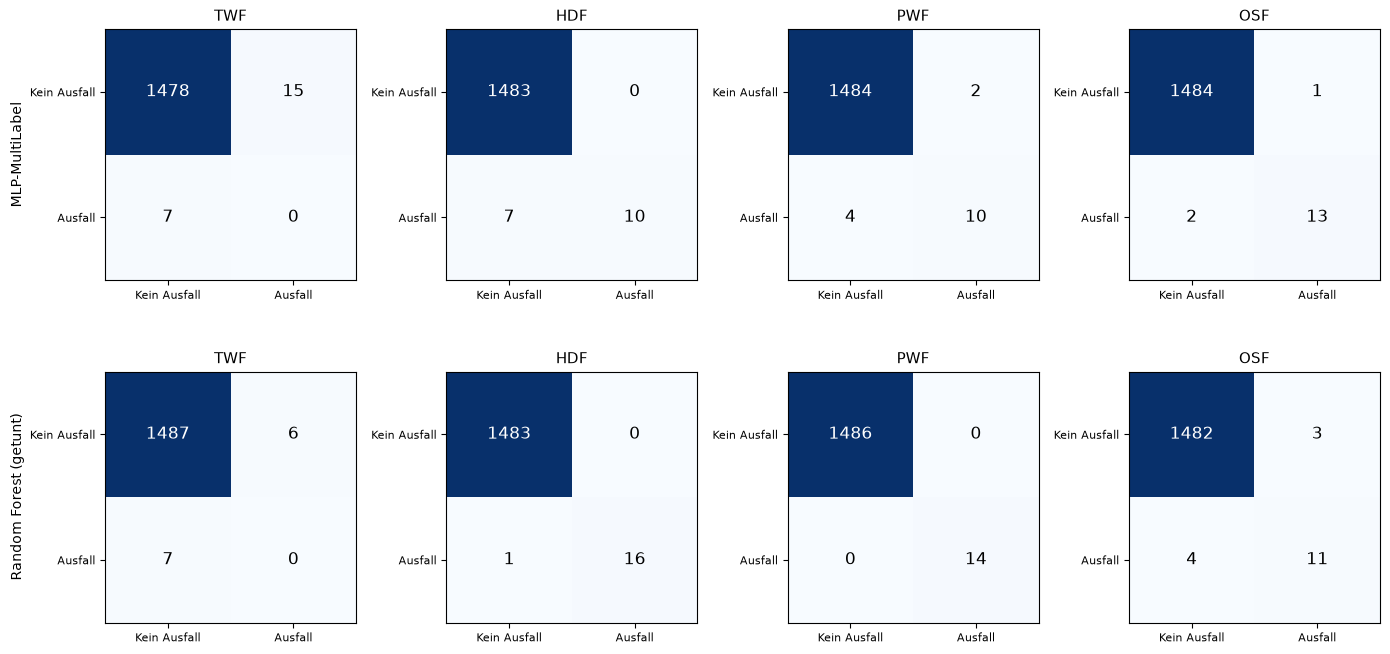

In [3]:
# 2 Zeilen (Modelle) x 4 Spalten (Labels), je Zelle eine 2x2-Konfusionsmatrix als Heatmap
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for row, (model_name, cms) in enumerate([("MLP-MultiLabel", mlp_cm), ("Random Forest (getunt)", rf_cm)]):
    for col_idx, label in enumerate(TARGET_COLUMNS):
        ax = axes[row, col_idx]
        cm = cms[label]
        im = ax.imshow(cm, cmap="Blues")
        for r in range(2):
            for c in range(2):
                ax.text(c, r, str(cm[r, c]), ha="center", va="center",
                        color="white" if cm[r, c] > cm.max() / 2 else "black", fontsize=12)
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["Kein Ausfall", "Ausfall"], fontsize=8)
        ax.set_yticklabels(["Kein Ausfall", "Ausfall"], fontsize=8)
        ax.set_title(f"{label}", fontsize=11)
        if col_idx == 0:
            ax.set_ylabel(model_name, fontsize=10)

plt.tight_layout()
plt.savefig(figure_path("comparison", "confusion_matrices_per_label.png"), dpi=150, bbox_inches="tight")
plt.show()

## 3. Tatsächliche vs. vorhergesagte Ausfälle je Fehlermodus

Ergänzend zu den aggregierten Konfusionsmatrizen: eine Ereignis-Zeitleiste über alle Testset-Beobachtungen (getunter Random Forest), die zeigt, *welche* konkreten Beobachtungen erkannt, verpasst oder fälschlich als Ausfall gemeldet wurden.

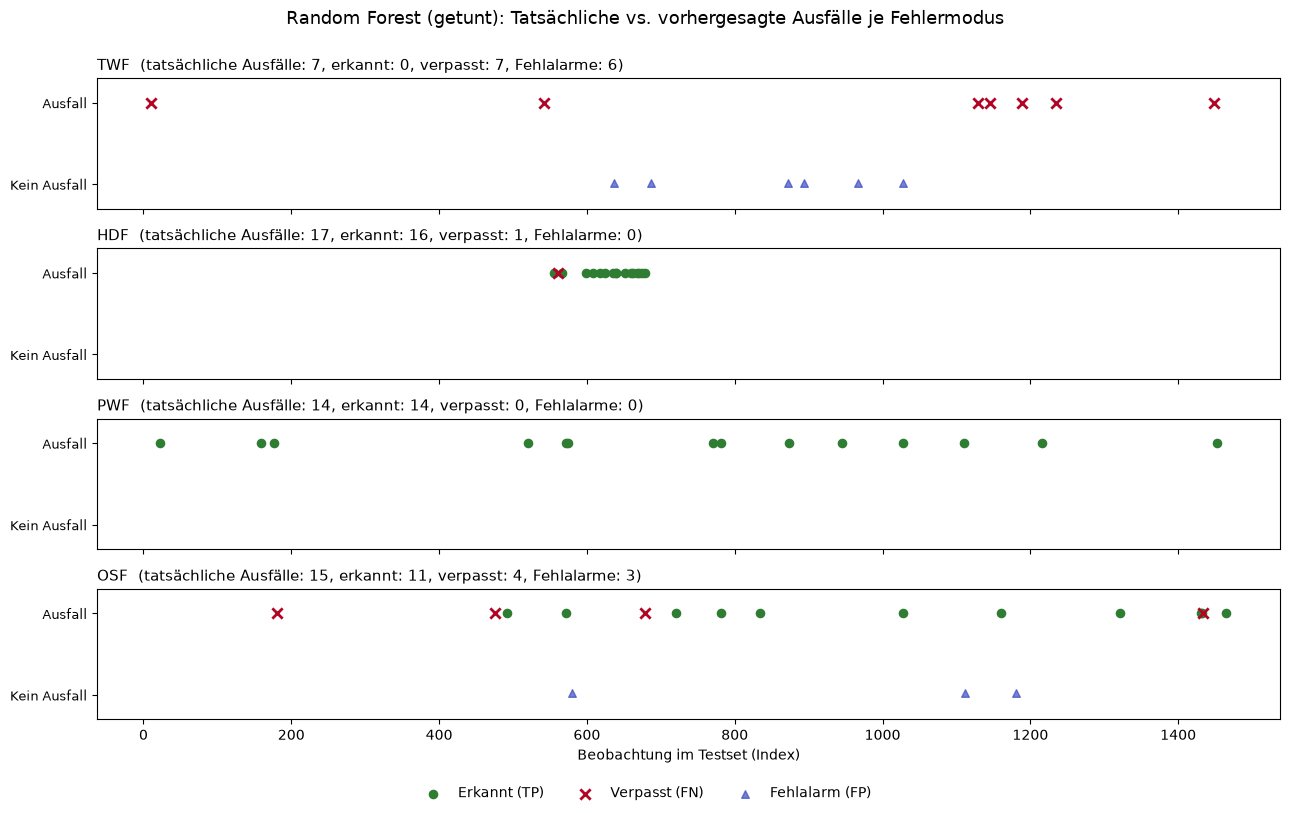

In [4]:
GREEN, RED_M, BLUE_M = "#2E7D32", "#b40426", "#3b4cc0"
rf_tuned_thresh_list = [thresholds["Random-Forest-MultiLabel-getunt"][col] for col in TARGET_COLUMNS]

fig, axes = plt.subplots(4, 1, figsize=(13, 8), sharex=True)
for i, (ax, label) in enumerate(zip(axes, TARGET_COLUMNS)):
    yt = rf_tuned_test["y_true"][:, i]
    yp = (rf_tuned_test["y_prob"][:, i] >= rf_tuned_thresh_list[i]).astype(int)
    x = np.arange(len(yt))

    # TN wird nicht dargestellt (die überwiegende Mehrheit, sonst nicht lesbar)
    tp = (yt == 1) & (yp == 1)
    fn = (yt == 1) & (yp == 0)
    fp = (yt == 0) & (yp == 1)

    ax.scatter(x[tp], np.ones(tp.sum()), color=GREEN, marker="o", s=35, label="Erkannt (TP)", zorder=3)
    ax.scatter(x[fn], np.ones(fn.sum()), color=RED_M, marker="x", s=55, linewidths=2, label="Verpasst (FN)", zorder=3)
    ax.scatter(x[fp], np.zeros(fp.sum()) + 0.02, color=BLUE_M, marker="^", s=30, label="Fehlalarm (FP)", zorder=2, alpha=0.7)

    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Kein Ausfall", "Ausfall"], fontsize=9)
    ax.set_ylim(-0.3, 1.3)
    ax.set_title(f"{label}  (tatsächliche Ausfälle: {int(yt.sum())}, erkannt: {int(tp.sum())}, "
                 f"verpasst: {int(fn.sum())}, Fehlalarme: {int(fp.sum())})", fontsize=11, loc="left")

axes[-1].set_xlabel("Beobachtung im Testset (Index)")
fig.suptitle("Random Forest (getunt): Tatsächliche vs. vorhergesagte Ausfälle je Fehlermodus", fontsize=13, y=1.00)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=10, frameon=False)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(figure_path("comparison", "actual_vs_predicted_rf.png"), dpi=150, bbox_inches="tight")
plt.show()

## 4. Wirkungsrichtung der Merkmale: Partial-Dependence-Plots (Random Forest)

Die Feature Importances aus Notebook 03 zeigen nur, *wie stark* ein Merkmal wirkt. Die Partial-Dependence-Kurve zeigt zusätzlich die Richtung: die durchschnittliche vorhergesagte Ausfallwahrscheinlichkeit in Abhängigkeit vom Merkmalswert, gemittelt über alle anderen Merkmale. Je Fehlermodus werden die numerischen Merkmale mit einer Importance von mindestens 0,15 gezeigt (höchstens zwei).

In [5]:
# Getuntes Modell, Scaler und standardisiertes Testset laden
rf_tuned = joblib.load("../models/random_forest_multilabel_tuned.pkl")
scaler = joblib.load("../models/scaler.pkl")
feature_cols = FEATURE_COLUMNS + ENCODED_TYPE_COLUMNS
X_test = pd.read_csv("../data/processed/test.csv")[feature_cols]

In [6]:
draw_partial_dependence(
    rf_tuned.estimators_, X_test, TARGET_COLUMNS, feature_cols, FEATURE_COLUMNS, scaler,
    path=figure_path("comparison", "rf_partial_dependence.png"),
)

# Variante mit größerer Schrift für die Präsentation
draw_partial_dependence(
    rf_tuned.estimators_, X_test, TARGET_COLUMNS, feature_cols, FEATURE_COLUMNS, scaler,
    path=figure_path("comparison", "rf_partial_dependence_compact.png"), font_scale=1.45,
)

## 5. Vergleichstabelle

In [8]:
comparison = pd.DataFrame({
    "MLP F1": mlp_metrics["f1"],
    "RF (getunt) F1": rf_tuned_metrics["f1"],
    "MLP PR-AUC": mlp_metrics["pr_auc"],
    "RF (getunt) PR-AUC": rf_tuned_metrics["pr_auc"],
})
comparison.round(3)

,MLP F1,RF (getunt) F1,MLP PR-AUC,RF (getunt) PR-AUC
label,,,,
TWF,0.000,0.000,0.054,0.059
HDF,0.741,0.970,0.976,1.000
PWF,0.769,1.000,0.878,1.000
OSF,0.897,0.759,0.978,0.890


## 6. Balkendiagramm: F1 je Fehlermodus

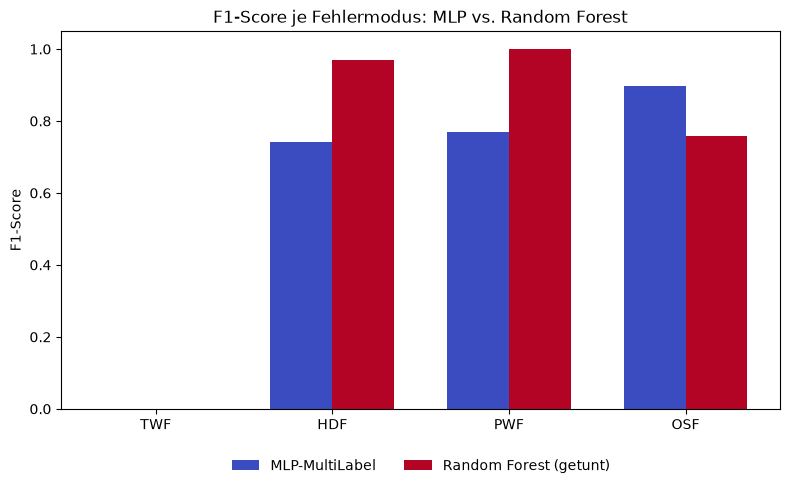

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(TARGET_COLUMNS))
width = 0.35
ax.bar(x - width/2, mlp_metrics["f1"], width, label="MLP-MultiLabel", color=BLUE)
ax.bar(x + width/2, rf_tuned_metrics["f1"], width, label="Random Forest (getunt)", color=RED)
ax.set_xticks(x)
ax.set_xticklabels(TARGET_COLUMNS)
ax.set_ylabel("F1-Score")
ax.set_title("F1-Score je Fehlermodus: MLP vs. Random Forest")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig(figure_path("comparison", "comparison_f1_per_label.png"), dpi=150, bbox_inches="tight")
plt.show()

## 7. Makro-Mittelwerte

TWF bleibt strukturell schwer vorhersagbar (Zufallskomponente) -- deshalb zusätzlich das Mittel ohne TWF, um die drei gut vorhersagbaren Modi fair zu vergleichen.

In [10]:
macro_avg_all = pd.DataFrame({
    "MLP": [mlp_metrics["f1"].mean(), mlp_metrics["pr_auc"].mean()],
    "RF (getunt)": [rf_tuned_metrics["f1"].mean(), rf_tuned_metrics["pr_auc"].mean()],
}, index=["F1 (Makro-Mittel, 4 Labels)", "PR-AUC (Makro-Mittel, 4 Labels)"])

macro_avg_no_twf = pd.DataFrame({
    "MLP": [mlp_metrics.drop("TWF")["f1"].mean(), mlp_metrics.drop("TWF")["pr_auc"].mean()],
    "RF (getunt)": [rf_tuned_metrics.drop("TWF")["f1"].mean(), rf_tuned_metrics.drop("TWF")["pr_auc"].mean()],
}, index=["F1 (Makro-Mittel, ohne TWF)", "PR-AUC (Makro-Mittel, ohne TWF)"])

print(macro_avg_all.round(3))
print()
print(macro_avg_no_twf.round(3))

                                   MLP  RF (getunt)
F1 (Makro-Mittel, 4 Labels)      0.602        0.682
PR-AUC (Makro-Mittel, 4 Labels)  0.721        0.737

                                   MLP  RF (getunt)
F1 (Makro-Mittel, ohne TWF)      0.802        0.909
PR-AUC (Makro-Mittel, ohne TWF)  0.944        0.963


## 8. Fazit

Kein Modell gewinnt durchgängig: Der Random Forest (getunt) ist bei HDF und PWF klar besser (F1 0,970 bzw. 1,000), das MLP bei OSF (F1 0,846 gegenüber 0,759). TWF bleibt bei beiden Modellen praktisch unbrauchbar (Zufallskomponente in der Datengenerierung). Ein baumbasiertes Verfahren ist bei diesem kleinen, gut strukturierten tabellarischen Datensatz also konkurrenzfähig bis überlegen. Es liefert dank `MultiOutputClassifier` zusätzlich separate Feature Importances je Fehlermodus (Notebook 03) sowie Partial-Dependence-Kurven in Abschnitt 4, die die bekannten Schwellen der Generierungsformeln (z. B. Temperaturdifferenz unter 8,6 K bei HDF) widerspiegeln.

In [11]:
comparison.to_csv(result_path("comparison", "final_comparison_table.csv"))
print("Vergleich abgeschlossen.")

Vergleich abgeschlossen.
